In [1]:
# Import essential libraries
import pandas as pd
import numpy as np

# Import the dataset from UCI ML repo
from ucimlrepo import fetch_ucirepo

# Fetch dataset (Sonar: Mines vs. Rocks, id=151)
sonar = fetch_ucirepo(id=151)

# Data as pandas DataFrame
X = sonar.data.features
y = sonar.data.targets

# Show basic info
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst 5 rows of features:")
print(X.head())
print("First 5 rows of target:")
print(y.head())

Features shape: (208, 60)
Target shape: (208, 1)

First 5 rows of features:
   Attribute1  Attribute2  Attribute3  Attribute4  Attribute5  Attribute6  \
0      0.0200      0.0371      0.0428      0.0207      0.0954      0.0986   
1      0.0453      0.0523      0.0843      0.0689      0.1183      0.2583   
2      0.0262      0.0582      0.1099      0.1083      0.0974      0.2280   
3      0.0100      0.0171      0.0623      0.0205      0.0205      0.0368   
4      0.0762      0.0666      0.0481      0.0394      0.0590      0.0649   

   Attribute7  Attribute8  Attribute9  Attribute10  ...  Attribute51  \
0      0.1539      0.1601      0.3109       0.2111  ...       0.0232   
1      0.2156      0.3481      0.3337       0.2872  ...       0.0125   
2      0.2431      0.3771      0.5598       0.6194  ...       0.0033   
3      0.1098      0.1276      0.0598       0.1264  ...       0.0241   
4      0.1209      0.2467      0.3564       0.4459  ...       0.0156   

   Attribute52  Attribute53 

In [2]:
# Basic info
print("Sonar features shape:", X.shape)
print("Sonar target shape:", y.shape)
print("First few rows of features:")
print(X.head())
print("First few target values:")
print(y.head())

# Feature names
print("\nFeature names:")
print(list(X.columns))

# Unique target values (class distribution)
print("\nTarget distribution:")
print(y.iloc[:, 0].value_counts())

# Check missing values per column
print("\nMissing values per feature (top 10):")
print(X.isnull().sum().sort_values(ascending=False).head(10))

# Feature summary statistics (first 10 features)
print("\nFeature summary statistics (first 10):")
print(X.describe().T.head(10))

# Correlation matrix: top 10 features correlated with the target (encoding target to 0,1 if needed)
# Convert the target labels to numbers for correlation (M=1, R=0)
y_numeric = y.iloc[:, 0].map({'M': 1, 'R': 0})
corrs = X.corrwith(y_numeric).abs()
print("\nTop 10 features most correlated with target:")
print(corrs.sort_values(ascending=False).head(10))


Sonar features shape: (208, 60)
Sonar target shape: (208, 1)
First few rows of features:
   Attribute1  Attribute2  Attribute3  Attribute4  Attribute5  Attribute6  \
0      0.0200      0.0371      0.0428      0.0207      0.0954      0.0986   
1      0.0453      0.0523      0.0843      0.0689      0.1183      0.2583   
2      0.0262      0.0582      0.1099      0.1083      0.0974      0.2280   
3      0.0100      0.0171      0.0623      0.0205      0.0205      0.0368   
4      0.0762      0.0666      0.0481      0.0394      0.0590      0.0649   

   Attribute7  Attribute8  Attribute9  Attribute10  ...  Attribute51  \
0      0.1539      0.1601      0.3109       0.2111  ...       0.0232   
1      0.2156      0.3481      0.3337       0.2872  ...       0.0125   
2      0.2431      0.3771      0.5598       0.6194  ...       0.0033   
3      0.1098      0.1276      0.0598       0.1264  ...       0.0241   
4      0.1209      0.2467      0.3564       0.4459  ...       0.0156   

   Attribute52 

In [3]:
# Fill missing values with column mean (if there are any)
X_filled = X.fillna(X.mean())

# Drop any non-numeric columns (Sonar is usually all numeric, but this is safe)
X_filled = X_filled.select_dtypes(include=['number'])

# Convert target from strings to integers: 'R' (Rock) = 0, 'M' (Mine) = 1
y_clean = y.iloc[:, 0].map({'R': 0, 'M': 1})

# Print shapes and a summary
print("Final feature shape:", X_filled.shape)
print("Final target shape:", y_clean.shape)
print("Number of missing values (after cleaning):", X_filled.isnull().sum().sum())
print("Target distribution (0 = Rock, 1 = Mine):")
print(y_clean.value_counts())

Final feature shape: (208, 60)
Final target shape: (208,)
Number of missing values (after cleaning): 0
Target distribution (0 = Rock, 1 = Mine):
class
1    111
0     97
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

# Typical 70% train, 30% test; stratify by class label to keep proportions
X_train, X_test, y_train, y_test = train_test_split(
    X_filled, y_clean,
    test_size=0.3,
    random_state=42,
    stratify=y_clean
)

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Train target distribution:\n", pd.Series(y_train).value_counts())
print("Test target distribution:\n", pd.Series(y_test).value_counts())


Train feature shape: (145, 60)
Test feature shape: (63, 60)
Train target distribution:
 class
1    77
0    68
Name: count, dtype: int64
Test target distribution:
 class
1    34
0    29
Name: count, dtype: int64


In [5]:
from sklearn.ensemble import ExtraTreesClassifier
import numpy as np

def get_variable_importance_and_muted(X_node, y_node, mute_rate=0.5, min_vars=5, random_state=42):
    et_model = ExtraTreesClassifier(n_estimators=50, random_state=random_state, class_weight='balanced')
    et_model.fit(X_node, np.array(y_node).ravel())
    importances = et_model.feature_importances_
    features_sorted = np.argsort(importances)
    n_total = len(importances)
    n_mute = max(int(mute_rate * n_total), n_total - min_vars)
    muted_features = features_sorted[:n_mute]
    kept_features = features_sorted[n_mute:]
    return kept_features, importances

class RLTNode:
    def __init__(self, X, y, kept_features, depth=0, max_depth=5, min_samples=20, mute_rate=0.5, min_vars=5):
        self.depth = depth
        self.X = X.iloc[:, kept_features]
        self.y = np.array(y).ravel()
        self.kept_features = kept_features
        self.left = None
        self.right = None
        self.split_feature = None
        self.split_value = None
        self.is_leaf = False
        if len(np.unique(self.y)) == 1 or len(self.y) < min_samples or depth >= max_depth or len(kept_features) <= min_vars:
            self.is_leaf = True
            if len(self.y) > 0 and np.issubdtype(self.y.dtype, np.integer):
                self.prediction = np.argmax(np.bincount(self.y))
            else:
                self.prediction = int(np.round(np.mean(self.y)))
            return
        et_model = ExtraTreesClassifier(n_estimators=20, random_state=42, class_weight='balanced')
        et_model.fit(self.X, self.y)
        importances = et_model.feature_importances_
        split_feature_idx = np.argmax(importances)
        self.split_feature = kept_features[split_feature_idx]
        split_values = self.X.iloc[:, split_feature_idx]
        self.split_value = np.median(split_values)
        left_mask = split_values <= self.split_value
        right_mask = split_values > self.split_value
        left_kept, _ = get_variable_importance_and_muted(self.X[left_mask], self.y[left_mask], mute_rate, min_vars)
        right_kept, _ = get_variable_importance_and_muted(self.X[right_mask], self.y[right_mask], mute_rate, min_vars)
        self.left = RLTNode(self.X[left_mask], self.y[left_mask], left_kept, depth+1, max_depth, min_samples, mute_rate, min_vars)
        self.right = RLTNode(self.X[right_mask], self.y[right_mask], right_kept, depth+1, max_depth, min_samples, mute_rate, min_vars)
    def predict_one(self, x_row):
        # Use iloc to avoid FutureWarning
        if self.is_leaf:
            return self.prediction
        if x_row.iloc[self.split_feature] <= self.split_value:
            return self.left.predict_one(x_row)
        else:
            return self.right.predict_one(x_row)

import random

class RLTForest:
    def __init__(self, n_estimators=10, max_depth=5, min_samples=20, mute_rate=0.5, min_vars=5, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples = min_samples
        self.mute_rate = mute_rate
        self.min_vars = min_vars
        self.random_state = random_state
        random.seed(self.random_state)
        self.trees = []
    def fit(self, X, y):
        n_samples = X.shape[0]
        init_kept_features = list(range(X.shape[1]))
        self.trees = []
        for i in range(self.n_estimators):
            idxs = np.random.choice(n_samples, n_samples, replace=True)
            X_boot = X.iloc[idxs].reset_index(drop=True)
            y_boot = y.iloc[idxs] if hasattr(y, 'iloc') else y[idxs]
            tree = RLTNode(X_boot, y_boot, init_kept_features, max_depth=self.max_depth,
                           min_samples=self.min_samples, mute_rate=self.mute_rate, min_vars=self.min_vars)
            self.trees.append(tree)
    def predict(self, X):
        preds = []
        for i in range(X.shape[0]):
            tree_preds = [tree.predict_one(X.iloc[i]) for tree in self.trees]
            preds.append(int(np.round(np.mean(tree_preds))))
        return preds


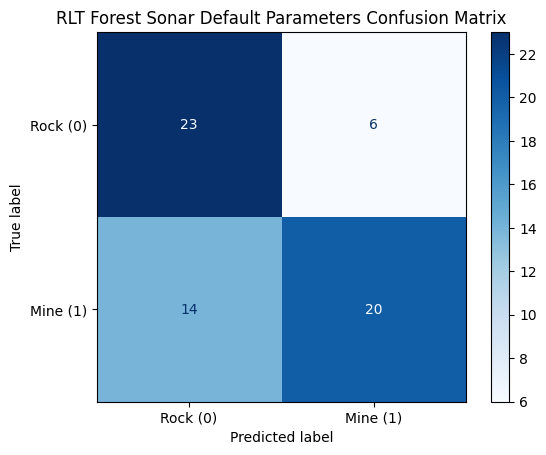

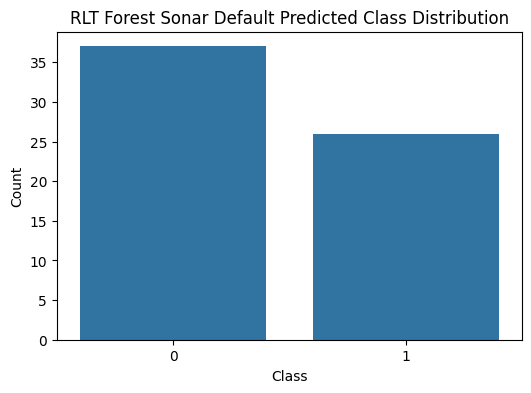

RLT Forest Sonar Default Accuracy: 0.6825396825396826
              precision    recall  f1-score   support

           0       0.62      0.79      0.70        29
           1       0.77      0.59      0.67        34

    accuracy                           0.68        63
   macro avg       0.70      0.69      0.68        63
weighted avg       0.70      0.68      0.68        63



In [6]:
# Train and evaluate RLT Forest with default parameters (Sonar dataset)

rlt_forest_default = RLTForest(
    n_estimators=10,
    max_depth=7,
    min_samples=15,
    mute_rate=0.5,
    min_vars=5,
    random_state=42
)
rlt_forest_default.fit(X_train, y_train)
rlt_preds_default = rlt_forest_default.predict(X_test)

# Visualizations and metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_default = confusion_matrix(y_test, rlt_preds_default)
cmd_default = ConfusionMatrixDisplay(cm_default, display_labels=["Rock (0)", "Mine (1)"])
cmd_default.plot(cmap='Blues')
plt.title("RLT Forest Sonar Default Parameters Confusion Matrix")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x=rlt_preds_default)
plt.title('RLT Forest Sonar Default Predicted Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

print("RLT Forest Sonar Default Accuracy:", accuracy_score(y_test, rlt_preds_default))
print(classification_report(y_test, rlt_preds_default))


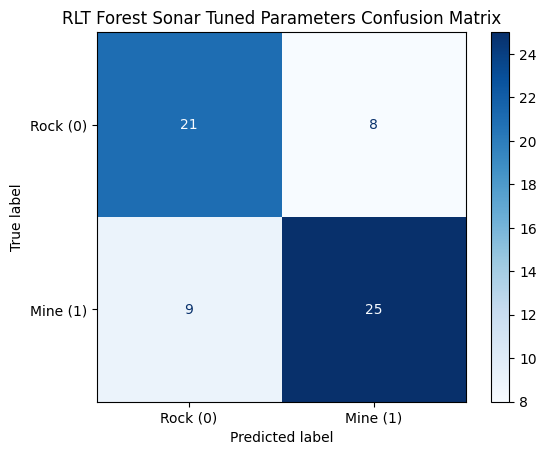

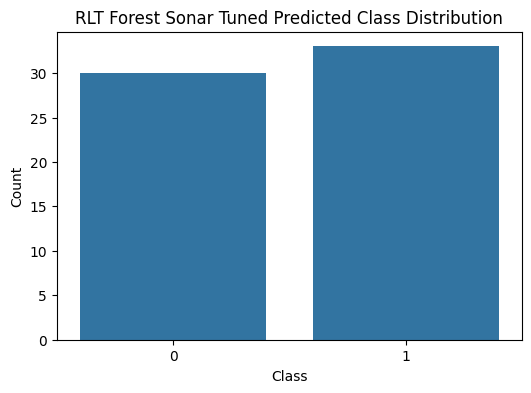

RLT Forest Sonar Tuned Accuracy: 0.7301587301587301
              precision    recall  f1-score   support

           0       0.70      0.72      0.71        29
           1       0.76      0.74      0.75        34

    accuracy                           0.73        63
   macro avg       0.73      0.73      0.73        63
weighted avg       0.73      0.73      0.73        63



In [7]:
# Train and evaluate RLT Forest with tuned parameters (Sonar dataset)

rlt_forest_tuned = RLTForest(
    n_estimators=30,     # more trees for stability
    max_depth=12,        # deeper splits
    min_samples=5,       # allow more splitting
    mute_rate=0.2,       # less muting to retain more features
    min_vars=5,
    random_state=42
)
rlt_forest_tuned.fit(X_train, y_train)
rlt_preds_tuned = rlt_forest_tuned.predict(X_test)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_tuned = confusion_matrix(y_test, rlt_preds_tuned)
cmd_tuned = ConfusionMatrixDisplay(cm_tuned, display_labels=["Rock (0)", "Mine (1)"])
cmd_tuned.plot(cmap='Blues')
plt.title("RLT Forest Sonar Tuned Parameters Confusion Matrix")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x=rlt_preds_tuned)
plt.title('RLT Forest Sonar Tuned Predicted Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

print("RLT Forest Sonar Tuned Accuracy:", accuracy_score(y_test, rlt_preds_tuned))
print(classification_report(y_test, rlt_preds_tuned))